# Лабораторная работа 2. Рекомендательные системы

Цель - сравнить три метода рекомендации 10 клипов, которых нет в известной истории пользователя.

In [1]:
import importlib.metadata
import subprocess
import sys
from warnings import filterwarnings

filterwarnings('ignore', message='IProgress not found.*')

PACKAGES = {
    'numpy': '1.26.4', 'pandas': '2.2.3', 'scipy': '1.14.1',
    'pyarrow': '18.1.0', 'implicit': '0.7.2', 'matplotlib': '3.9.4',
    'threadpoolctl': '3.5.0',
}
missing = []
for name, version in PACKAGES.items():
    try:
        installed = importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        missing.append(f'{name}=={version}')
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

In [2]:
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass
from pathlib import Path
import hashlib
import json
import time
from urllib.request import urlopen

import numpy as np
import pandas as pd
from scipy import sparse
from implicit.cpu.als import AlternatingLeastSquares
from threadpoolctl import threadpool_limits


REPOSITORY = "deepvk/VK-LSVD"
REVISION = "084a18386e149a454dd6dbe0123478e75c6b09ce"
SUBSET = "ur0.01_ir0.01"
POSITIVE_REACTIONS = ["like", "share", "bookmark"]
FEEDBACK_COLUMNS = POSITIVE_REACTIONS + ["click_on_author", "open_comments", "dislike"]

SIGNAL_RULE = {"completion_threshold": 0.5, "skip_threshold": 0.1,
               "watch_weight": 1., "dislike_weight": 2., "skip_weight": 0.25}


import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED, K = 42, 10
DATA_DIR = Path('data/vk_lsvd')
RESULT_DIR = Path('results/vk_lsvd')
FIGURE_DIR = RESULT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.constrained_layout.use': True})
COLORS = {'MostPop': '#5470a6', 'ItemKNN': '#c98538', 'ALS': '#2b8a78'}

def save_figure(name):
    plt.savefig(FIGURE_DIR / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()

def show_table(frame, filename):
    frame.to_csv(RESULT_DIR / filename, index=True)
    display(frame)

## 1. Датасет и постановка задачи

Используем официальную подвыборку VK-LSVD ur0.01_ir0.01 из
[публикации авторов на Hugging Face](https://huggingface.co/datasets/deepvk/VK-LSVD).
Она содержит 4 044 900 показов, 90 178 пользователей и 125 018 клипов.
Рекомендуем клипы пользователям; в исходном соревновании решается обратная задача.

Интерес определяем по реакциям и относительному времени просмотра
$r=timespent/duration$. Для веса используем $q=\min(r,1)$.

| Сигнал | Условие | Метка и вес |
| --- | --- | --- |
| Dislike | Есть dislike, даже вместе с like или долгим просмотром | $p=0,\ w=2$ |
| Положительный | Нет dislike; есть like/share/bookmark или $r\ge0{,}5$ | $p=1,\ w=1+q$ |
| Ранний пропуск | Нет реакций и $r\le0{,}1$ | $p=0,\ w=0{,}25$ |
| Неопределённый показ | Остальные наблюдения | Без обучающего веса; исключается из выдачи |
| Нет наблюдения | Пары нет в истории | Интерес неизвестен; клип доступен для рекомендации |

При duration=0 или значении 255 в одном из полей отношение не используем:
способ ограничения шкалы не описан. Сохраняем реакции, для положительной реакции берём $q=0$.
Отношение больше единицы может означать повторный просмотр внутри показа;
ограничение веса не даёт ему расти без границы. Повторные пары пользователь-клип проверяем отдельно.

Отсутствие лайка не означает dislike. Открытие комментариев и переход к автору сами по себе не означают одобрения.
Пороги и веса фиксированы до сравнения. timespent - поле данных; качество оценивается метриками ниже.

In [3]:
def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        while block := stream.read(4 * 1024 * 1024):
            digest.update(block)
    return digest.hexdigest()


def download_data(root):
    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    paths = [f"subsamples/{SUBSET}/train/week_{week:02}.parquet" for week in range(25)]
    paths += [f"subsamples/{SUBSET}/validation/week_25.parquet",
              f"subsamples/{SUBSET}/test/week_26.parquet",
              "metadata/items_metadata.parquet", "metadata/users_metadata.parquet"]
    manifest_path = root / "manifest.json"
    old = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}
    cached = {entry["path"]: entry for entry in old.get("files", [])}

    def fetch(path):
        destination = root / path
        url = f"https://huggingface.co/datasets/{REPOSITORY}/resolve/{REVISION}/{path}"
        entry = cached.get(path, {})
        valid = (old.get("revision") == REVISION and destination.exists()
                 and destination.stat().st_size == entry.get("size")
                 and file_sha256(destination) == entry.get("sha256"))
        if not valid:
            destination.parent.mkdir(parents=True, exist_ok=True)
            temporary = destination.with_suffix(".part")
            with urlopen(url, timeout=60) as source, temporary.open("wb") as output:
                while block := source.read(4 * 1024 * 1024):
                    output.write(block)
            temporary.replace(destination)
        return {"path": path, "url": url, "size": destination.stat().st_size,
                "sha256": file_sha256(destination)}

    with ThreadPoolExecutor(max_workers=4) as executor:
        records = list(executor.map(fetch, paths))
    manifest = {"repository": REPOSITORY, "revision": REVISION,
                "subset": SUBSET, "files": records}
    manifest_path.write_text(json.dumps(manifest, indent=2))
    return manifest


def add_feedback(events):
    result = events.copy()
    duration = result.duration.astype(float)
    watch = result.timespent.astype(float)

    valid = duration.between(1, 254) & watch.between(0, 254)
    ratio = (watch / duration.where(valid)).where(valid)
    completion = ratio.clip(upper=1).fillna(0)
    reaction = result[POSITIVE_REACTIONS].any(axis=1)
    auxiliary = result[["open_comments", "click_on_author"]].any(axis=1)
    dislike = result.dislike.astype(bool)
    positive = ~dislike & (reaction | ratio.ge(SIGNAL_RULE["completion_threshold"]))
    skip = (~dislike & ~reaction & ~auxiliary
            & ratio.le(SIGNAL_RULE["skip_threshold"]))
    result["watch_ratio"] = ratio.astype(np.float32)
    result["positive"] = positive
    result["signal"] = pd.Categorical(np.select(
        [dislike, positive, skip], ["dislike", "positive", "skip"], default="neutral"))
    result["weight"] = np.select(
        [dislike, positive, skip],
        [SIGNAL_RULE["dislike_weight"], 1 + SIGNAL_RULE["watch_weight"] * completion,
         SIGNAL_RULE["skip_weight"]], default=0).astype(np.float32)
    return result


def load_data(root):
    root = Path(root)
    frames = []
    for week in range(27):
        folder = "train" if week < 25 else ("validation" if week == 25 else "test")
        frame = pd.read_parquet(root / f"subsamples/{SUBSET}/{folder}/week_{week:02}.parquet")
        frame["week"] = np.uint8(week)
        frames.append(frame)
    events = pd.concat(frames, ignore_index=True)
    items = pd.read_parquet(
        root / "metadata/items_metadata.parquet",
        columns=["item_id", "author_id", "duration"],
        filters=[("item_id", "in", events.item_id.unique().tolist())],
    )
    users = pd.read_parquet(
        root / "metadata/users_metadata.parquet",
        columns=["user_id", "age", "gender", "geo"],
        filters=[("user_id", "in", events.user_id.unique().tolist())],
    )
    events = events.merge(items[["item_id", "duration"]], on="item_id", how="left",
                          validate="many_to_one")
    return add_feedback(events), items, users


def split_by_week(events):
    if not events.week.between(0, 26).all():
        raise ValueError("Expected weeks 00-26 of the pinned official subset")
    return (events.loc[events.week < 25].copy(),
            events.loc[events.week == 25].copy(),
            events.loc[events.week == 26].copy())

In [4]:
manifest = download_data(DATA_DIR)
(RESULT_DIR / 'data_manifest.json').write_text(json.dumps(manifest, indent=2))
events, items, users = load_data(DATA_DIR)
train, validation, test = split_by_week(events)
assert (len(events), events.user_id.nunique(), events.item_id.nunique()) == (4044900, 90178, 125018)
display(events.head())

,user_id,item_id,place,platform,agent,timespent,like,dislike,share,bookmark,click_on_author,open_comments,week,duration,watch_ratio,positive,signal,weight
0,450187,1250577,0,0,0,1,False,False,False,False,False,False,0,31,0.032258,False,skip,0.25000
1,2388051,5691360,1,0,0,15,False,False,False,False,False,False,0,14,1.071429,True,positive,2.00000
2,2200275,1250577,0,0,0,31,False,False,False,False,False,False,0,31,1.000000,True,positive,2.00000
3,1093829,4460025,1,1,1,40,False,False,False,False,False,False,0,77,0.519481,True,positive,1.51948
4,3541498,1817772,1,1,1,2,False,False,False,False,False,False,0,48,0.041667,False,skip,0.25000


## 2. Разведочный анализ и качество данных

Проверяем пропуски, дубли и связь с метаданными во всей выгрузке.
Распределения изучаем по train. Значения за границей 1,5 IQR отмечаем, но не удаляем автоматически.
NaN в watch_ratio обозначает неопределённое отношение времени.

In [5]:
show_table(pd.DataFrame({'dtype': events.dtypes.astype(str), 'missing': events.isna().sum()}), 'schema.csv')
raw_columns = [c for c in events.columns if c not in ['positive', 'signal', 'weight', 'watch_ratio']]
quality = pd.Series({
    'Пропуски в исходных полях': int(events[raw_columns].isna().sum().sum()),
    'Полные дубли строк': int(events[raw_columns].duplicated().sum()),
    'Повторные пары user-item': int(events.duplicated(['user_id', 'item_id']).sum()),
    'Дубли item_id в метаданных': int(items.item_id.duplicated().sum()),
    'Дубли user_id в метаданных': int(users.user_id.duplicated().sum()),
    'Клипы без метаданных': int((~events.item_id.isin(items.item_id)).sum()),
    'Пользователи без метаданных': int((~events.user_id.isin(users.user_id)).sum()),
    'Пропуски в метаданных клипов': int(items.isna().sum().sum()),
    'Пропуски в метаданных пользователей': int(users.isna().sum().sum()),
}, name='Количество').to_frame()
show_table(quality, 'data_quality.csv')
assert quality.iloc[:, 0].eq(0).all()
watch_audit = pd.Series({
    'Нулевая длительность, показы train': int(train.duration.eq(0).sum()),
    'Длительность 255, показы train': int(train.duration.eq(255).sum()),
    'Время просмотра 255, показы train': int(train.timespent.eq(255).sum()),
    'Неопределённое отношение времени, train': int(train.watch_ratio.isna().sum()),
    'Известное отношение больше единицы, train': int(train.watch_ratio.gt(1).sum()),
    'Dislike с положительной реакцией или долгим просмотром, train':
        int((train.dislike & (train[POSITIVE_REACTIONS].any(axis=1) | train.watch_ratio.ge(.5))).sum()),
    'Положительные примеры только по времени, train':
        int((train.positive & ~train[POSITIVE_REACTIONS].any(axis=1)).sum()),
}, name='Количество').to_frame()
show_table(watch_audit, 'watch_audit.csv')
assert not (train.positive & train.dislike).any()

,dtype,missing
user_id,uint32,0
item_id,uint32,0
place,uint8,0
platform,uint8,0
agent,uint8,0
timespent,uint8,0
like,bool,0
dislike,bool,0
share,bool,0
bookmark,bool,0


,Количество
Пропуски в исходных полях,0
Полные дубли строк,0
Повторные пары user-item,0
Дубли item_id в метаданных,0
Дубли user_id в метаданных,0
Клипы без метаданных,0
Пользователи без метаданных,0
Пропуски в метаданных клипов,0
Пропуски в метаданных пользователей,0


,Количество
"Нулевая длительность, показы train",0
"Длительность 255, показы train",0
"Время просмотра 255, показы train",3078
"Неопределённое отношение времени, train",3078
"Известное отношение больше единицы, train",651406
"Dislike с положительной реакцией или долгим просмотром, train",548
"Положительные примеры только по времени, train",1702832


,Значение
Показы train,3.720328e+06
Положительные примеры train,1.830766e+06
Доля положительных примеров,4.920980e-01
Пользователи train,8.937100e+04
Клипы train,1.204150e+05
Разреженность положительной матрицы,9.998299e-01
Медиана показов на пользователя,1.800000e+01
Медиана показов на клип,3.000000e+00
Пользователи без положительной истории,8.134000e+03


,Количество,Доля
signal,,
positive,1830766,0.492098
dislike,1091,0.000293
skip,932103,0.250543
neutral,956368,0.257066


,Доля показов
like,0.028411
share,0.006382
bookmark,0.001067
click_on_author,0.002028
open_comments,0.011796
dislike,0.000293


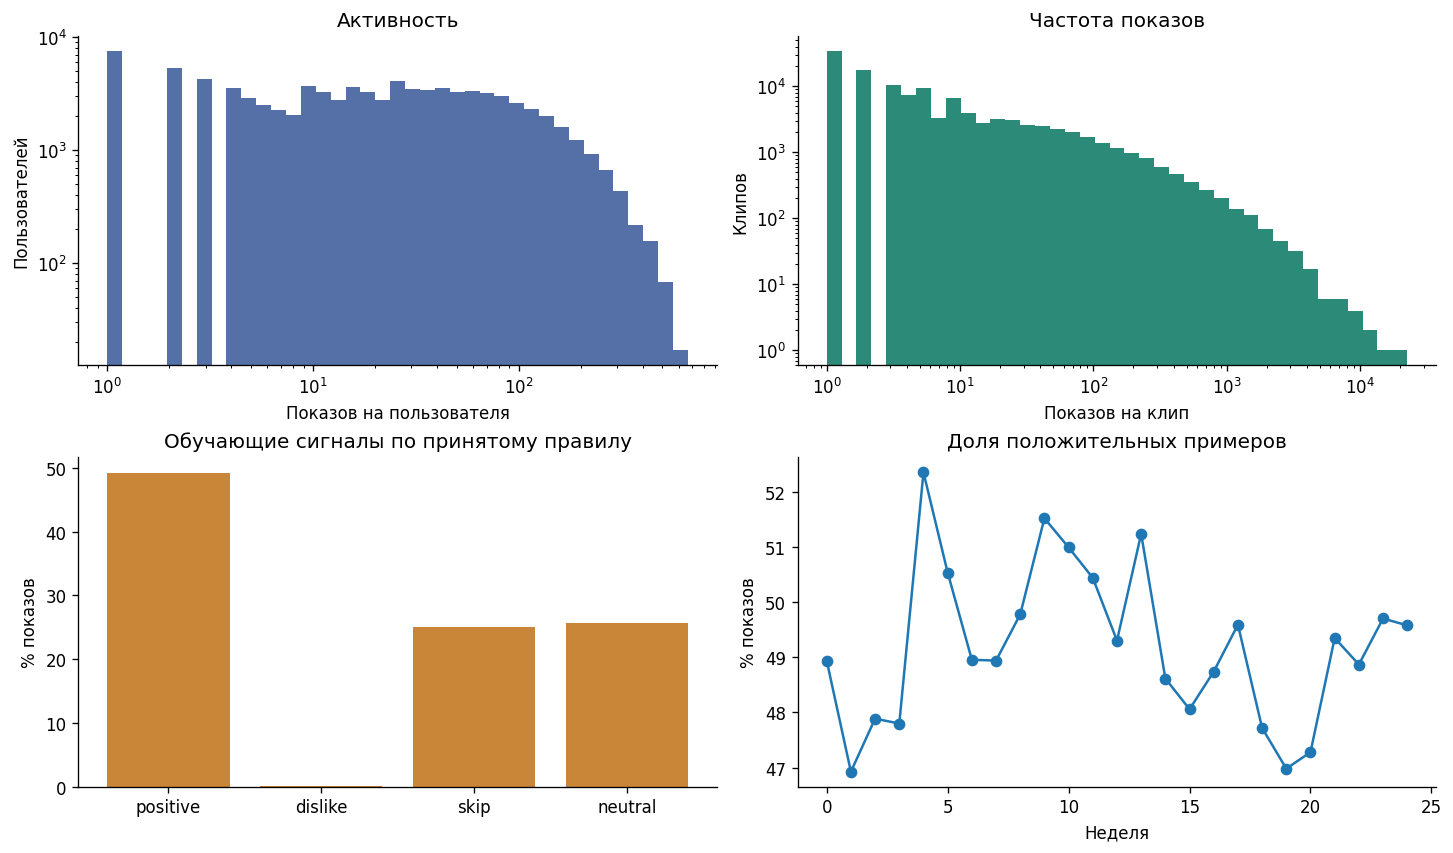

,Медиана,P99,Максимум,Граница IQR,Выше IQR
Признак,,,,,
Показы пользователя,18.00000,290.000000,664,125.00,7311
Показы клипа,3.00000,496.000000,22610,26.00,18540
"Время просмотра, с",9.00000,135.000000,255,68.00,206799
Отношение времени,0.45098,2.833333,50.400002,2.35,54969


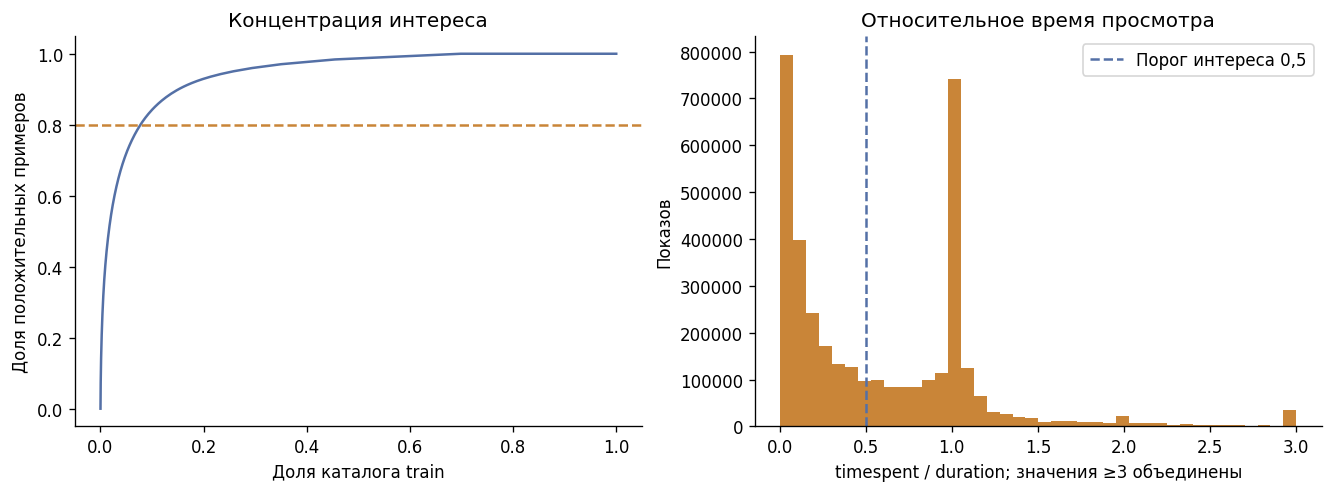

Положительны 49.21% показов train. На 9,332 клипов (7.75% каталога) приходится 80% положительных примеров. Медиана истории - 18 показов. По неделям доля положительных примеров меняется от 46.92% до 52.35%. На гистограмме отношения времени значения от 3 объединены в последний столбец.

In [6]:
user_activity = train.groupby('user_id').size()
item_exposure = train.groupby('item_id').size()
positive_popularity = train.loc[train.positive].groupby('item_id').size()
statistics = pd.Series({
    'Показы train': len(train), 'Положительные примеры train': int(train.positive.sum()),
    'Доля положительных примеров': train.positive.mean(),
    'Пользователи train': train.user_id.nunique(), 'Клипы train': train.item_id.nunique(),
    'Разреженность положительной матрицы': 1 - train.positive.sum() / (train.user_id.nunique() * train.item_id.nunique()),
    'Медиана показов на пользователя': user_activity.median(),
    'Медиана показов на клип': item_exposure.median(),
    'Пользователи без положительной истории': train.user_id.nunique() - train.loc[train.positive, 'user_id'].nunique(),
}, name='Значение').to_frame()
show_table(statistics, 'train_statistics.csv')
signals = train.signal.value_counts().reindex(['positive', 'dislike', 'skip', 'neutral'], fill_value=0)
show_table(pd.DataFrame({'Количество': signals, 'Доля': signals / len(train)}), 'train_signals.csv')
show_table(train[FEEDBACK_COLUMNS].mean().rename('Доля показов').to_frame(), 'train_feedback.csv')

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes[0, 0].hist(user_activity, bins=np.geomspace(1, user_activity.max() + 1, 40), color='#5470a6')
axes[0, 0].set(xscale='log', yscale='log', xlabel='Показов на пользователя', ylabel='Пользователей', title='Активность')
axes[0, 1].hist(item_exposure, bins=np.geomspace(1, item_exposure.max() + 1, 40), color='#2b8a78')
axes[0, 1].set(xscale='log', yscale='log', xlabel='Показов на клип', ylabel='Клипов', title='Частота показов')
axes[1, 0].bar(signals.index, signals / len(train) * 100, color='#c98538')
axes[1, 0].set(ylabel='% показов', title='Обучающие сигналы по принятому правилу')
weekly = train.groupby('week').agg(events=('user_id', 'size'), positives=('positive', 'sum'))
axes[1, 1].plot(weekly.index, weekly.positives / weekly.events * 100, marker='o')
axes[1, 1].set(xlabel='Неделя', ylabel='% показов', title='Доля положительных примеров')
save_figure('eda_activity_feedback')

def concentration(values):
    ordered = values.sort_values(ascending=False).to_numpy()
    cumulative = np.cumsum(ordered) / ordered.sum()
    return ordered, cumulative, int(np.searchsorted(cumulative, .8) + 1)

pop_sorted, cumulative, head_count = concentration(positive_popularity)
outliers = []
for name, values in [('Показы пользователя', user_activity), ('Показы клипа', item_exposure),
                     ('Время просмотра, с', train.timespent), ('Отношение времени', train.watch_ratio.dropna())]:
    q1, q3 = values.quantile([.25, .75]); boundary = q3 + 1.5 * (q3 - q1)
    outliers.append({'Признак': name, 'Медиана': values.median(), 'P99': values.quantile(.99),
                     'Максимум': values.max(), 'Граница IQR': boundary, 'Выше IQR': int((values > boundary).sum())})
show_table(pd.DataFrame(outliers).set_index('Признак'), 'outliers.csv')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(np.r_[0, np.arange(1, len(pop_sorted) + 1) / train.item_id.nunique(), 1],
             np.r_[0, cumulative, 1], color='#5470a6')
axes[0].axhline(.8, color='#c98538', linestyle='--')
axes[0].set(xlabel='Доля каталога train', ylabel='Доля положительных примеров', title='Концентрация интереса')
axes[1].hist(train.watch_ratio.dropna().clip(upper=3), bins=40, color='#c98538')
axes[1].axvline(.5, color='#5470a6', linestyle='--', label='Порог интереса 0,5')
axes[1].set(xlabel='timespent / duration; значения ≥3 объединены', ylabel='Показов', title='Относительное время просмотра')
axes[1].legend()
save_figure('eda_popularity_watchtime')
display(Markdown(
    f'Положительны {100 * train.positive.mean():.2f}% показов train. '
    f'На {head_count:,} клипов ({100 * head_count / train.item_id.nunique():.2f}% каталога) приходится 80% положительных примеров. '
    f'Медиана истории - {user_activity.median():.0f} показов. '
    f'По неделям доля положительных примеров меняется от {100 * (weekly.positives / weekly.events).min():.2f}% '
    f'до {100 * (weekly.positives / weekly.events).max():.2f}%. '
    'На гистограмме отношения времени значения от 3 объединены в последний столбец.'
))

## 3. Обучающая и тестовая выборки

| Выборка | Недели | Назначение |
| --- | --- | --- |
| train | 00-24 | Обучение и статистики |
| validation | 25 | Подбор параметров |
| test | 26 | Итоговая оценка |

После подбора переобучаем модели на 00-25. Каталог, популярность и маска просмотренного
строятся только по истории до оцениваемой недели. Длительность считаем неизменным свойством клипа;
глобальный train_interactions_rank не используем.

Рекомендуем из всего известного каталога, исключая любые предыдущие показы.
Холодные клипы сохраняем в эталонных ответах. Оцениваем всех пользователей с релевантными
ответами; при отсутствии положительной истории используем MostPop.
Будущие время и реакции нужны только для эталона и не передаются моделям при ранжировании.

In [7]:
@dataclass
class Matrices:
    user_ids: np.ndarray
    item_ids: np.ndarray
    positive: sparse.csr_matrix
    negative: sparse.csr_matrix
    seen: sparse.csr_matrix
    popularity: np.ndarray


def build_matrices(history):
    if history.duplicated(["user_id", "item_id"]).any():
        raise ValueError("Repeated user-item pairs need an explicit aggregation policy")
    user_ids = np.sort(history.user_id.unique())
    item_ids = np.sort(history.item_id.unique())
    rows = pd.Index(user_ids).get_indexer(history.user_id)
    columns = pd.Index(item_ids).get_indexer(history.item_id)
    shape = (len(user_ids), len(item_ids))
    seen = sparse.csr_matrix((np.ones(len(history), dtype=np.float32), (rows, columns)), shape=shape)
    seen.data[:] = 1
    mask = history.positive.to_numpy(dtype=bool)
    positive = sparse.csr_matrix(
        (history.weight.to_numpy()[mask], (rows[mask], columns[mask])), shape=shape,
    )
    negative_mask = history.signal.isin(["dislike", "skip"]).to_numpy()
    negative = sparse.csr_matrix(
        (history.weight.to_numpy()[negative_mask], (rows[negative_mask], columns[negative_mask])),
        shape=shape,
    )
    popularity = np.asarray((positive > 0).sum(axis=0)).ravel().astype(np.float32)
    return Matrices(user_ids, item_ids, positive, negative, seen, popularity)


def evaluation_targets(holdout):
    truth = holdout.loc[holdout.positive].groupby("user_id").item_id.agg(set).to_dict()
    return np.array(sorted(truth)), truth


def split_audit(matrices, holdout):
    target_users, truth = evaluation_targets(holdout)
    positive = holdout.loc[holdout.positive]
    mapped = pd.Index(matrices.user_ids).get_indexer(target_users)
    warm = mapped >= 0
    warm[warm] &= np.diff(matrices.positive.indptr)[mapped[warm]] > 0
    catalog = set(matrices.item_ids)
    reachable = []
    seen_targets = 0
    for user, row in zip(target_users, mapped):
        seen = set(matrices.item_ids[matrices.seen[row].indices]) if row >= 0 else set()
        seen_targets += len(truth[user] & seen)
        reachable.append(len((truth[user] & catalog) - seen) / len(truth[user]))
    return {
        "Events": len(holdout), "PositiveEvents": len(positive),
        "EvaluatedUsers": len(target_users), "ColdUsers": int((mapped < 0).sum()),
        "PopularityFallbackUsers": int((~warm).sum()),
        "ColdTargetEvents": int((~positive.item_id.isin(matrices.item_ids)).sum()),
        "SeenTargetPairs": seen_targets,
        "ReachableRecallUpperBound": float(np.mean(reachable)),
        "CandidateItems": len(matrices.item_ids),
    }

In [8]:
splits = pd.DataFrame([
    {'split': name, 'first_week': int(frame.week.min()), 'last_week': int(frame.week.max()),
     'events': len(frame), 'users': frame.user_id.nunique(), 'items': frame.item_id.nunique(),
     'positive_events': int(frame.positive.sum())}
    for name, frame in [('train', train), ('validation', validation), ('test', test)]
]).set_index('split')
show_table(splits, 'splits.csv')
assert train.week.max() == 24 and validation.week.unique().tolist() == [25] and test.week.unique().tolist() == [26]
assert len(train) + len(validation) + len(test) == len(events)
train_matrices = build_matrices(train)
validation_users, validation_truth = evaluation_targets(validation)
validation_audit = split_audit(train_matrices, validation)
show_table(pd.DataFrame([validation_audit], index=['validation']), 'validation_audit.csv')

,first_week,last_week,events,users,items,positive_events
split,,,,,,
train,0,24,3720328,89371,120415,1830766
validation,25,25,170111,43370,13126,83594
test,26,26,154461,42199,11814,74069


,Events,PositiveEvents,EvaluatedUsers,ColdUsers,PopularityFallbackUsers,ColdTargetEvents,SeenTargetPairs,ReachableRecallUpperBound,CandidateItems
validation,170111,83594,32261,218,528,22751,0,0.721705,120415


## 4. Методы рекомендаций

Пусть $X_{ui}=w_{ui}$ для положительного примера и 0 иначе.

### 4.1. MostPop - популярность

Оценка - число положительных пар клипа в обучающей истории:
$$s(u,i)=pop(i)=\sum_v\mathbb{1}[X_{vi}>0].$$

Это базовый метод для проверки пользы персонализации. Время влияет через метку интереса.
Dislike и пропуск не увеличивают популярность; отдельного штрафа за них нет.

### 4.2. ItemKNN - сходство клипов

Косинус между взвешенными столбцами измеряет сходство по общим пользователям:
$$sim(i,j)=\frac{X_{:i}^TX_{:j}}{\|X_{:i}\|\|X_{:j}\|},\qquad
s(u,j)=\sum_iX_{ui}\,sim(i,j)\mathbb{1}[j\in N_L(i)].$$

Для каждого клипа оставляем L других ближайших соседей. Время влияет на сходства и профиль
пользователя. Отрицательные сигналы не входят в положительную матрицу; отталкивание от
похожих клипов не моделируется. Произведения считаются разреженными блоками.

### 4.3. Implicit ALS - факторизация

$$\min_{A,B}\sum_{u,i}c_{ui}(p_{ui}-a_u^Tb_i)^2+\lambda(\|A\|_F^2+\|B\|_F^2).$$

Для положительных примеров $p=1$, для dislike и пропуска $p=0$;
уверенность $c=1+\alpha w$. Остальные пары имеют $p=0,c=1$.
В implicit передаём $+c$ для положительных примеров и $-c$ для отрицательных.
Математическая уверенность равна модулю записи. Библиотечный alpha=1 сохраняет готовые веса.

Все методы исключают просмотренные клипы. При равных оценках выбирается более популярный
клип, затем меньший item_id. У ItemKNN это заполняет список при недостатке ненулевых соседств.

In [9]:
def fit_itemknn(positive, neighbors=50, block_size=1024):
    norms = np.sqrt(np.asarray(positive.power(2).sum(axis=0)).ravel())
    inverse = np.divide(1., norms, out=np.zeros_like(norms), where=norms > 0)
    normalized = (positive @ sparse.diags(inverse)).tocsc()
    blocks = []
    n_items = positive.shape[1]
    for start in range(0, n_items, block_size):
        similarities = (normalized[:, start:start + block_size].T @ normalized).tocsr()
        for local_row in range(similarities.shape[0]):
            lo, hi = similarities.indptr[local_row:local_row + 2]
            indices = similarities.indices[lo:hi]
            values = similarities.data[lo:hi]
            values[indices == start + local_row] = 0
            if len(values) > neighbors:
                order = np.lexsort((indices, -values))
                values[order[neighbors:]] = 0
        similarities.eliminate_zeros()
        blocks.append(similarities)
    return sparse.vstack(blocks, format="csr")


def als_confidence(matrices, alpha=10.):
    if not np.isfinite(alpha) or alpha <= 0:
        raise ValueError("alpha must be positive and finite")
    confidence = matrices.positive - matrices.negative
    confidence.eliminate_zeros()
    confidence.data = np.sign(confidence.data) * (1. + alpha * np.abs(confidence.data))
    return confidence.tocsr()


def fit_als(matrices, factors=32, alpha=10., regularization=0.1, iterations=20, seed=42):
    confidence = als_confidence(matrices, alpha)
    with threadpool_limits(limits=1):
        model = AlternatingLeastSquares(
            factors=factors, regularization=regularization, alpha=1.,
            iterations=iterations, random_state=seed, num_threads=1,
        )
        model.fit(confidence, show_progress=False)
    return model


def top_k(scores, seen, k, fallback_order):
    scores = np.asarray(scores).copy()
    if k <= 0 or k > len(scores) or not np.isfinite(scores).all():
        raise ValueError("Expected finite scores and 1 <= K <= catalog size")
    scores[seen] = -np.inf
    if np.count_nonzero(np.isfinite(scores)) < k:
        raise ValueError("Fewer than K unseen, finite-scored candidates")
    threshold = np.partition(scores, len(scores) - k)[-k]
    above = np.flatnonzero(scores > threshold)
    tied = fallback_order[scores[fallback_order] == threshold][:k - len(above)]
    candidates = np.concatenate([above, tied])

    ranks = np.empty(len(scores), dtype=np.int32)
    ranks[fallback_order] = np.arange(len(scores))
    return candidates[np.lexsort((ranks[candidates], -scores[candidates]))]


def recommend(name, model, matrices, evaluation_users, k=10, batch_size=64):
    user_index = pd.Index(matrices.user_ids).get_indexer(evaluation_users)
    fallback_order = np.argsort(-matrices.popularity, kind="stable")
    has_positive = np.diff(matrices.positive.indptr) > 0
    result = []
    with threadpool_limits(limits=1):
        for start in range(0, len(evaluation_users), batch_size):
            mapped = user_index[start:start + batch_size]
            warm = mapped >= 0
            warm[warm] &= has_positive[mapped[warm]]
            scores = np.tile(matrices.popularity, (len(mapped), 1))
            if name == "ItemKNN":
                scores[warm] = (matrices.positive[mapped[warm]] @ model).toarray()
            elif name == "ALS":
                scores[warm] = model.user_factors[mapped[warm]] @ model.item_factors.T
            elif name != "MostPop":
                raise ValueError(f"Unknown model: {name}")
            for local, row in enumerate(mapped):
                seen = matrices.seen[row].indices if row >= 0 else np.array([], dtype=int)
                columns = top_k(scores[local], seen, k, fallback_order)
                result.append(matrices.item_ids[columns])
    return np.asarray(result)

## 5. Метрики

$R_u$ - K рекомендаций, $T_u$ - все релевантные клипы будущей недели,
$h_r=\mathbb{1}[R_{u,r}\in T_u]$. Первые три метрики усредняем по пользователям.

| Метрика | Формула | Смысл |
| --- | --- | --- |
| Precision@K ↑ | $\sum h_r/K$ | Доля попаданий в списке |
| Recall@K ↑ | $\sum h_r/\lvert T_u\rvert$ | Доля найденных релевантных клипов |
| NDCG@K ↑ | $\frac{\sum_{r=1}^K h_r/\log_2(r+1)}{\sum_{r=1}^{\min(K,\lvert T_u\rvert)}1/\log_2(r+1)}$ | Качество порядка |

Относительная новизна измеряет разницу самоинформации выдачи модели и MostPop:
$$p_{train}(i)=\frac{pop(i)+1}{\sum_{j\in I}pop(j)+|I|},\qquad
SI@K(R)=\frac1K\sum_{i\in R}-\log_2p_{train}(i),$$
$$RelativeNovelty@K(M)=\frac1{|U|}\sum_u[SI@K(R_u(M))-SI@K(R_u(MostPop))].$$

Вероятности считаются по обучающей истории: 00-24 для validation, 00-25 для test.
Сглаживание с единицей исключает бесконечности. Единица измерения - бит на клип сверх MostPop.
У самого MostPop получается 0 по общей формуле. Пользователи, K, каталог и маски просмотренного одинаковы.
Это принятое в работе определение относительной новизны; оно не использует пересечение списков.

Для разнообразия каталога $f_i$ - число выдач клипа, $n=|I|$;
$f_{(j)}$ отсортированы по возрастанию и включают нули.

| Метрика | Формула | Смысл |
| --- | --- | --- |
| CatalogCoverage@K ↑ | $\lvert\bigcup_uR_u\rvert/n$ | Охваченная доля каталога |
| CatalogGini@K ↓ | $\frac{2\sum_{j=1}^njf_{(j)}}{n\sum_jf_j}-\frac{n+1}{n}$ | Концентрация выдачи |

Gini равен 0 при равномерной выдаче; максимум - $(n-1)/n$.
Новизна и охват не заменяют точность рекомендаций.

In [10]:
def ranking_metrics(recommendations, evaluation_users, truth):
    if (recommendations.ndim != 2 or len(recommendations) != len(evaluation_users)
            or not len(evaluation_users) or recommendations.shape[1] == 0
            or len(np.unique(evaluation_users)) != len(evaluation_users)):
        raise ValueError("Expected a nonempty aligned cohort and recommendation matrix")
    k = recommendations.shape[1]
    discount = 1. / np.log2(np.arange(2, k + 2))
    records = []
    for user, recommended in zip(evaluation_users, recommendations):
        relevant = truth[user]
        if not relevant or len(np.unique(recommended)) != k:
            raise ValueError("Evaluation requires positive targets and K distinct recommendations")
        hits = np.isin(recommended, list(relevant)).astype(float)
        ideal = discount[:min(k, len(relevant))].sum()
        records.append({
            "user_id": user,
            f"Precision@{k}": hits.mean(),
            f"Recall@{k}": hits.sum() / len(relevant),
            f"NDCG@{k}": np.dot(hits, discount) / ideal,
        })
    return pd.DataFrame(records).set_index("user_id")


def catalog_metrics(recommendation_columns, popularity, reference_columns):
    if (recommendation_columns.ndim != 2 or recommendation_columns.size == 0
            or recommendation_columns.shape != reference_columns.shape):
        raise ValueError("Reference must have the same users, order, and K")
    k = recommendation_columns.shape[1]
    n_items = len(popularity)
    if (n_items == 0 or not np.isfinite(popularity).all() or (popularity < 0).any()
            or (recommendation_columns < 0).any() or (recommendation_columns >= n_items).any()
            or (reference_columns < 0).any() or (reference_columns >= n_items).any()):
        raise ValueError("Invalid catalog, popularity, or recommendation columns")
    counts = np.bincount(recommendation_columns.ravel(), minlength=n_items)
    sorted_counts = np.sort(counts)
    gini = (2 * np.dot(np.arange(1, n_items + 1), sorted_counts)
            / (n_items * sorted_counts.sum()) - (n_items + 1) / n_items)
    probability = (popularity.astype(np.float64) + 1) / (popularity.sum(dtype=np.float64) + n_items)
    information = -np.log2(probability)
    relative = (information[recommendation_columns].mean(axis=1)
                - information[reference_columns].mean(axis=1)).mean()
    return {
        f"CatalogCoverage@{k}": np.count_nonzero(counts) / n_items,
        f"CatalogGini@{k}": float(gini),
        f"RelativeNovelty@{k}": float(relative),
        "UniqueRecommendedItems": int(np.count_nonzero(counts)),
    }


def evaluate(recommendations, evaluation_users, truth, matrices, reference):
    for lists in (recommendations, reference):
        if not np.isin(lists, matrices.item_ids).all():
            raise ValueError("Recommendations must belong to the training catalog")
    per_user = ranking_metrics(recommendations, evaluation_users, truth)
    columns = np.searchsorted(matrices.item_ids, recommendations)
    metrics = per_user.mean().to_dict()
    reference_columns = np.searchsorted(matrices.item_ids, reference)
    metrics.update(catalog_metrics(columns, matrices.popularity, reference_columns))
    metrics["EvaluatedUsers"] = len(evaluation_users)
    return metrics, per_user

In [11]:
example = pd.DataFrame({
    'user_id': [1] * 5, 'item_id': [10, 20, 30, 40, 50],
    'timespent': [1, 10, 40, 255, 20], 'duration': [20, 20, 20, 20, 0],
    'like': [False, False, True, False, False], 'dislike': [False, False, True, False, False],
    'share': [False] * 5, 'bookmark': [False] * 5,
    'open_comments': [False] * 5, 'click_on_author': [False] * 5,
})
labelled = add_feedback(example)
assert labelled.signal.tolist() == ['skip', 'positive', 'dislike', 'neutral', 'neutral']
assert labelled.weight.tolist() == [.25, 1.5, 2., 0., 0.]
assert als_confidence(build_matrices(labelled), alpha=4).toarray().tolist() == [[-2., 7., -9., 0., 0.]]
toy = ranking_metrics(np.array([[10, 20]]), np.array([1]), {1: {20, 999}})
assert toy.loc[1, 'Precision@2'] == .5 and toy.loc[1, 'Recall@2'] == .5
assert np.isclose(toy.loc[1, 'NDCG@2'], (1 / np.log2(3)) / (1 + 1 / np.log2(3)))
reference = np.array([[0, 1], [0, 1]])
assert catalog_metrics(reference.copy(), np.array([9., 4., 0., 0.]), reference)['RelativeNovelty@2'] == 0
assert catalog_metrics(reference, np.ones(4), reference)['CatalogGini@2'] == .5
assert catalog_metrics(np.array([[0, 2], [1, 3]]), np.ones(4), reference)['CatalogCoverage@2'] == 1
assert top_k(np.array([4., 3., 2.]), np.array([0]), 2, np.arange(3)).tolist() == [1, 2]
example['week'] = [0, 24, 25, 26, 26]
past = build_matrices(split_by_week(add_feedback(example))[0])
example.loc[example.week >= 25, 'timespent'] = 0
same_past = build_matrices(split_by_week(add_feedback(example))[0])
assert (past.positive != same_past.positive).nnz == 0
assert past.item_ids.tolist() == [10, 20]

## 6. Подбор параметров

Проверяем ItemKNN с 20 и 50 соседями; ALS с 32 и 64 факторами, α=10 и 40.
Регуляризация 0,1 и 20 итераций фиксированы. Выбираем по NDCG@10 на validation,
при равенстве - по Recall@10, затем по порядку конфигураций. Пороги интереса и веса не меняем.

In [12]:
configurations = [('MostPop', {})]
configurations += [('ItemKNN', {'neighbors': neighbors}) for neighbors in (20, 50)]
configurations += [('ALS', {'factors': factors, 'alpha': alpha, 'regularization': .1, 'iterations': 20})
                   for factors in (32, 64) for alpha in (10., 40.)]
validation_reference = recommend('MostPop', None, train_matrices, validation_users, k=K)
validation_rows = []
for config_id, (name, parameters) in enumerate(configurations):
    started = time.perf_counter()
    model = (fit_itemknn(train_matrices.positive, **parameters) if name == 'ItemKNN'
             else fit_als(train_matrices, **parameters, seed=SEED) if name == 'ALS' else None)
    fit_seconds = time.perf_counter() - started
    started = time.perf_counter()
    recs = recommend(name, model, train_matrices, validation_users, k=K)
    recommend_seconds = time.perf_counter() - started
    metrics, _ = evaluate(recs, validation_users, validation_truth, train_matrices, validation_reference)
    validation_rows.append({'config_id': config_id, 'Model': name, 'Parameters': json.dumps(parameters, sort_keys=True),
                            'FitSeconds': fit_seconds, 'RecommendSeconds': recommend_seconds, **metrics})
    del model
validation_results = pd.DataFrame(validation_rows).set_index('config_id')
show_table(validation_results, 'validation_results.csv')
selected = (validation_results.reset_index()
            .sort_values([f'NDCG@{K}', f'Recall@{K}', 'config_id'], ascending=[False, False, True])
            .groupby('Model', sort=False).head(1).set_index('Model'))
selected_parameters = {name: json.loads(selected.loc[name, 'Parameters']) for name in COLORS}
(RESULT_DIR / 'selected_parameters.json').write_text(json.dumps(selected_parameters, indent=2))
show_table(selected[['Parameters', f'NDCG@{K}', f'Recall@{K}']], 'selected_validation.csv')

,Model,Parameters,FitSeconds,RecommendSeconds,Precision@10,Recall@10,NDCG@10,CatalogCoverage@10,CatalogGini@10,RelativeNovelty@10,UniqueRecommendedItems,EvaluatedUsers
config_id,,,,,,,,,,,,
0,MostPop,{},3.330060e-07,38.049682,0.000081,0.000351,0.000217,0.000282,0.999894,0.000000,34,32261
1,ItemKNN,"{""neighbors"": 20}",6.502852e+00,18.004806,0.005313,0.021111,0.013431,0.317917,0.932641,4.969460,38282,32261
2,ItemKNN,"{""neighbors"": 50}",6.546172e+00,19.039046,0.005474,0.021767,0.013519,0.289200,0.948018,4.277753,34824,32261
3,ALS,"{""alpha"": 10.0, ""factors"": 32, ""iterations"": 2...",8.258936e+00,44.962099,0.005217,0.023689,0.013590,0.015480,0.996707,1.774619,1864,32261
4,ALS,"{""alpha"": 40.0, ""factors"": 32, ""iterations"": 2...",8.169593e+00,45.739528,0.005347,0.025305,0.014282,0.029340,0.994309,2.159170,3533,32261
5,ALS,"{""alpha"": 10.0, ""factors"": 64, ""iterations"": 2...",1.665560e+01,46.763903,0.006488,0.029739,0.016922,0.023186,0.994920,2.108983,2792,32261
6,ALS,"{""alpha"": 40.0, ""factors"": 64, ""iterations"": 2...",1.645586e+01,45.967209,0.005800,0.027696,0.015474,0.037470,0.992614,2.335394,4512,32261


,Parameters,NDCG@10,Recall@10
Model,,,
ALS,"{""alpha"": 10.0, ""factors"": 64, ""iterations"": 2...",0.016922,0.029739
ItemKNN,"{""neighbors"": 50}",0.013519,0.021767
MostPop,{},0.000217,0.000351


## 7. Сравнение на test

Переобучаем выбранные модели на train + validation и оцениваем на неделе 26.
Параметры по test не подбираем.

In [13]:
final_history = pd.concat([train, validation], ignore_index=True)
assert final_history.week.max() == 25
final_matrices = build_matrices(final_history)
test_users, test_truth = evaluation_targets(test)
test_audit = split_audit(final_matrices, test)
show_table(pd.DataFrame([validation_audit, test_audit], index=['validation', 'test']), 'evaluation_audit.csv')
test_reference = recommend('MostPop', None, final_matrices, test_users, k=K)
test_rows, test_recommendations = [], {}
for name in COLORS:
    parameters = selected_parameters[name]
    started = time.perf_counter()
    model = (fit_itemknn(final_matrices.positive, **parameters) if name == 'ItemKNN'
             else fit_als(final_matrices, **parameters, seed=SEED) if name == 'ALS' else None)
    fit_seconds = time.perf_counter() - started
    started = time.perf_counter()
    recs = recommend(name, model, final_matrices, test_users, k=K)
    recommend_seconds = time.perf_counter() - started
    metrics, per_user = evaluate(recs, test_users, test_truth, final_matrices, test_reference)
    test_rows.append({'Model': name, 'FitSeconds': fit_seconds, 'RecommendSeconds': recommend_seconds, **metrics})
    test_recommendations[name] = recs
    per_user.to_csv(RESULT_DIR / f'test_users_{name}.csv')
    np.savez_compressed(RESULT_DIR / f'recommendations_{name}.npz', user_id=test_users, item_id=recs)
    del model
results = pd.DataFrame(test_rows).set_index('Model')
show_table(results, 'test_results.csv')
assert results.loc['MostPop', f'RelativeNovelty@{K}'] == 0
mapped = pd.Index(final_matrices.user_ids).get_indexer(test_users)
for recs in test_recommendations.values():
    assert recs.shape == (len(test_users), K) and np.isin(recs, final_matrices.item_ids).all()
    for row, recommended in zip(mapped, recs):
        assert len(np.unique(recommended)) == K
        if row >= 0:
            assert not np.isin(recommended, final_matrices.item_ids[final_matrices.seen[row].indices]).any()

,Events,PositiveEvents,EvaluatedUsers,ColdUsers,PopularityFallbackUsers,ColdTargetEvents,SeenTargetPairs,ReachableRecallUpperBound,CandidateItems
validation,170111,83594,32261,218,528,22751,0,0.721705,120415
test,154461,74069,30569,168,457,6786,0,0.907596,123743


,FitSeconds,RecommendSeconds,Precision@10,Recall@10,NDCG@10,CatalogCoverage@10,CatalogGini@10,RelativeNovelty@10,UniqueRecommendedItems,EvaluatedUsers
Model,,,,,,,,,,
MostPop,4.579779e-07,38.023495,0.000101,0.000444,0.000175,0.000283,0.999896,0.000000,35,30569
ItemKNN,6.994161e+00,18.499496,0.006438,0.028288,0.017220,0.268540,0.953336,4.138674,33230,30569
ALS,1.730693e+01,45.284322,0.008044,0.039022,0.021541,0.022692,0.994880,2.091584,2808,30569


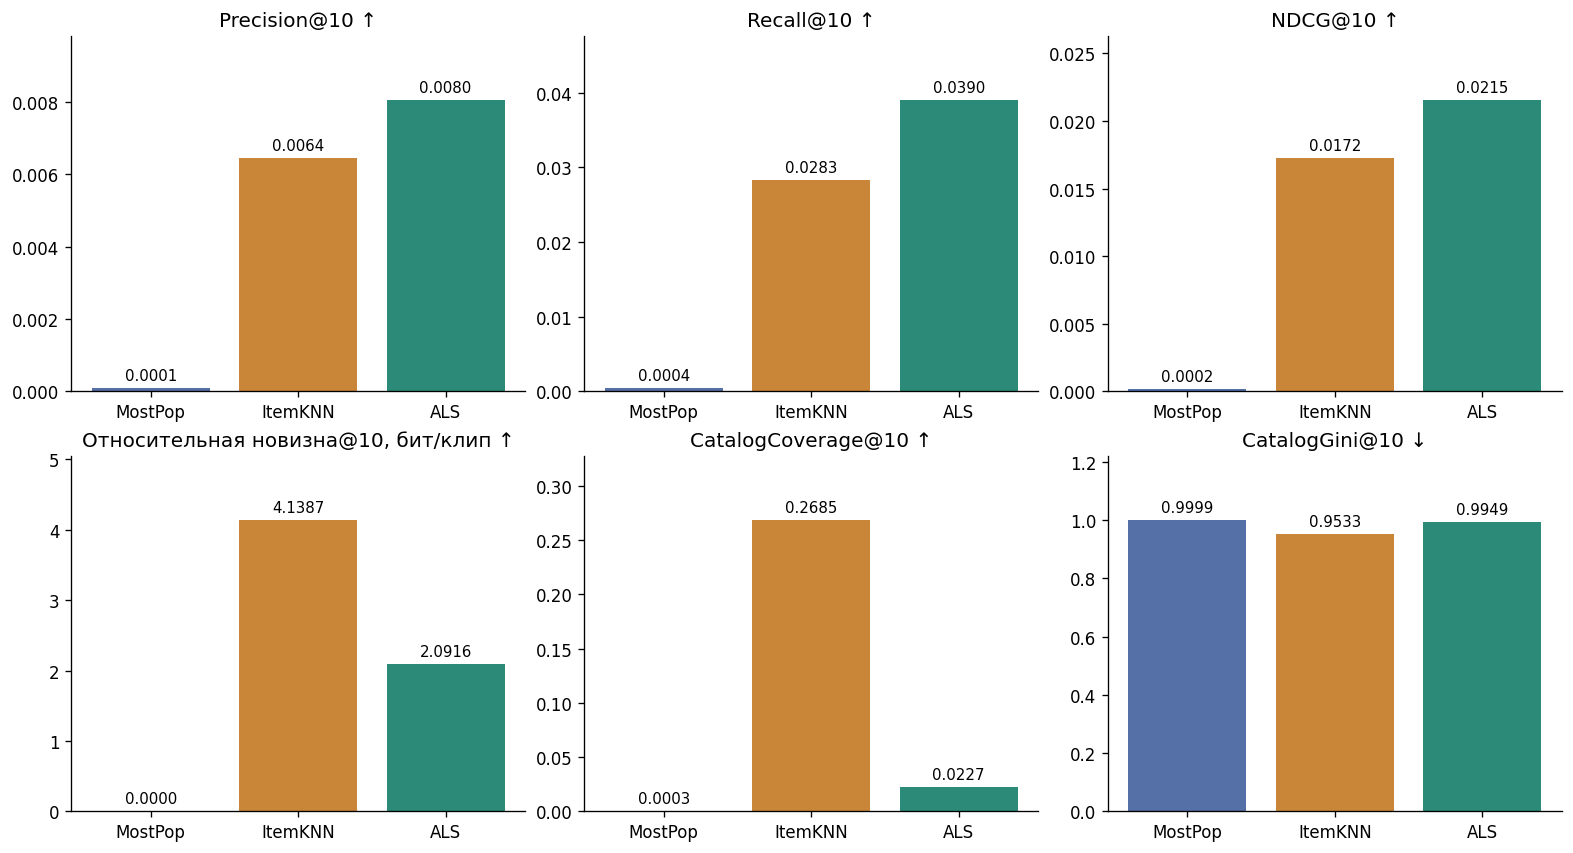

Максимальный NDCG@10 у ALS: 0.021541. Наибольший охват у ItemKNN: 26.85% каталога.

Оценено 30,569 пользователей из 42,199 пользователей test. Для 457 используется MostPop из-за отсутствия положительной истории. Все 6,786 холодных положительных событий сохранены в ответах. Ограничение каталога снижает достижимый средний Recall до 0.9076 ещё до ограничения top-10.

In [14]:
metrics_to_plot = ['Precision', 'Recall', 'NDCG', 'RelativeNovelty', 'CatalogCoverage', 'CatalogGini']
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, metric in zip(axes.ravel(), metrics_to_plot):
    key = f'{metric}@{K}'
    bars = ax.bar(results.index, results[key], color=[COLORS[name] for name in results.index])
    ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=9)
    label = 'Относительная новизна@10, бит/клип' if metric == 'RelativeNovelty' else key
    ax.set_title(label + (' ↓' if metric == 'CatalogGini' else ' ↑'))
    ax.margins(y=.22)
save_figure('test_quality_diversity')
best = results[f'NDCG@{K}'].idxmax()
widest = results[f'CatalogCoverage@{K}'].idxmax()
interpretation = (
    f'Максимальный NDCG@{K} у {best}: {results.loc[best, f"NDCG@{K}"]:.6f}. '
    f'Наибольший охват у {widest}: {100 * results.loc[widest, f"CatalogCoverage@{K}"]:.2f}% каталога.\n\n'
    f'Оценено {len(test_users):,} пользователей из {test.user_id.nunique():,} пользователей test. '
    f'Для {test_audit["PopularityFallbackUsers"]:,} используется MostPop из-за отсутствия положительной истории. '
    f'Все {test_audit["ColdTargetEvents"]:,} холодных положительных событий сохранены в ответах. '
    f'Ограничение каталога снижает достижимый средний Recall до {test_audit["ReachableRecallUpperBound"]:.4f} '
    f'ещё до ограничения top-{K}.'
)
(RESULT_DIR / 'interpretation.md').write_text(interpretation)
display(Markdown(interpretation))

## 8. Выводы и улучшения

ALS чаще находил подходящие клипы и ставил их выше в списке. ItemKNN уступил по точности,
но предложил больше разных и менее популярных клипов.

Для этой задачи выбираем ALS. Дальше можно учесть давность просмотров и содержание клипов,
а также подобрать веса просмотров и реакций.